# 数据分析作业

**姓名：黄河俊天　学号：22301170100**

本 notebook 按作业要求逐题完成，每题一个 section：
1. 数据预处理包括哪些步骤？
2. 什么是异常值？
3. 复现简洁美观的 sin 和 cos 图
4. 使用 `plt.subplot` 绘制多列散点图
5. 画出箱线图，并解释箱体上的各个部分
6*. 选择 seaborn 中的数据集 penguins，探索数据集的特征，并绘出散点图、箱体图、小提琴图、成对图；并使用 PCA 分析

## 0. 环境准备

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

# 中文显示设置
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei"]
plt.rcParams["axes.unicode_minus"] = False

print("环境就绪")

环境就绪


## 第1题　数据预处理包括哪些步骤？

数据预处理是将原始数据转换为适合分析/建模的高质量数据的过程，主要包括以下步骤：

| 步骤 | 主要内容 |
|---|---|
| **1. 数据清洗** | 处理**缺失值**（删除、均值/中位数/众数填充、插值）；处理**异常值**（检测、删除或修正）；去除**重复值**；平滑噪声数据 |
| **2. 数据集成** | 将多个数据源合并成一个数据集；实体识别与匹配；消除冗余属性；解决数据冲突 |
| **3. 数据变换** | **标准化**（Z-score，均值为0方差为1）、**归一化**（Min-Max缩放到[0,1]）；离散化（连续值分箱）；类别变量编码（One-hot、Label Encoding）；对数/平方根变换 |
| **4. 数据规约** | 维度规约（如 PCA 主成分分析）；数量规约（抽样、聚类代替）；数据压缩 |
| **5. 数据划分**（建模前） | 训练集/测试集划分；类别不平衡处理（过采样、欠采样） |

核心目的：**提高数据质量 → 提高分析和模型结果的可靠性**。

## 第2题　什么是异常值？

**异常值（Outlier）**是指明显偏离数据集整体分布或其余样本观测值的数值，它与其他数据点呈现出"格格不入"的特征。

**产生原因：**
- 测量误差、仪器故障
- 数据录入错误
- 抽样误差
- 真实存在的小概率事件（此时异常值本身可能有重要研究价值）

**常用检测方法：**

| 方法 | 判定规则 |
|---|---|
| 3σ 原则 | 近似正态分布下，偏离均值超过 3 倍标准差（\|x−μ\|>3σ） |
| 箱线图 IQR 法 | 小于 **Q1−1.5×IQR** 或大于 **Q3+1.5×IQR**（IQR=Q3−Q1），即箱线图须线之外的点 |
| Z-score / 修正Z | 标准化后分数绝对值过大 |
| 模型法 | 孤立森林（Isolation Forest）、DBSCAN、LOF 等 |

**处理方式：** 删除、当作缺失值填充、盖帽法（截断到上下限）、分箱，或保留并单独分析（当异常值代表真实现象时）。

## 第3题　复现简洁美观的 sin 和 cos 图（PPT 36）

要点：`np.linspace` 生成平滑曲线；坐标轴刻度用 π 表示；去掉上、右边框并把左、下边框移到原点；添加图例。

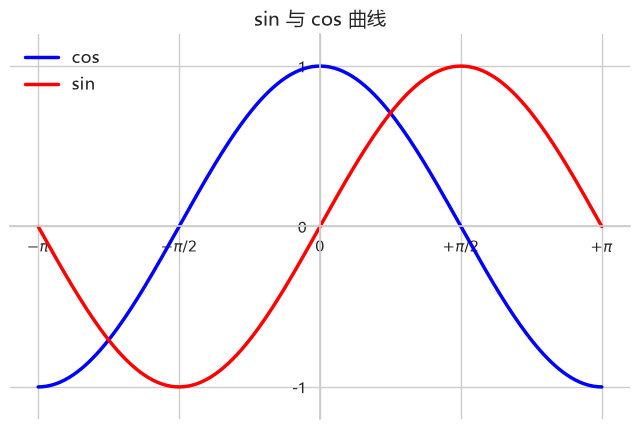

In [2]:
X = np.linspace(-np.pi, np.pi, 256, endpoint=True)
C, S = np.cos(X), np.sin(X)

plt.figure(figsize=(8, 5), dpi=100)
plt.plot(X, C, color="blue", linewidth=2.5, linestyle="-", label="cos")
plt.plot(X, S, color="red",  linewidth=2.5, linestyle="-", label="sin")

# 把坐标轴边框移到原点，去掉上、右边框
ax = plt.gca()
ax.spines["right"].set_color("none")
ax.spines["top"].set_color("none")
ax.spines["left"].set_position(("data", 0))
ax.spines["bottom"].set_position(("data", 0))

# 刻度用 π 表示
plt.xticks([-np.pi, -np.pi/2, 0, np.pi/2, np.pi],
           [r"$-\pi$", r"$-\pi/2$", r"$0$", r"$+\pi/2$", r"$+\pi$"])
plt.yticks([-1, 0, 1])

plt.xlim(-np.pi * 1.1, np.pi * 1.1)
plt.ylim(-1.2, 1.2)
plt.legend(loc="upper left", frameon=False, fontsize=12)
plt.title("sin 与 cos 曲线", fontsize=14)
plt.show()

## 第4题　使用 `plt.subplot` 绘制多列散点图（PPT 52）

用 `plt.subplot(行, 列, 序号)` 在一张画布上布置多个子图；这里以 penguins 数据集中 4 对数值特征组合为例，按种类着色。

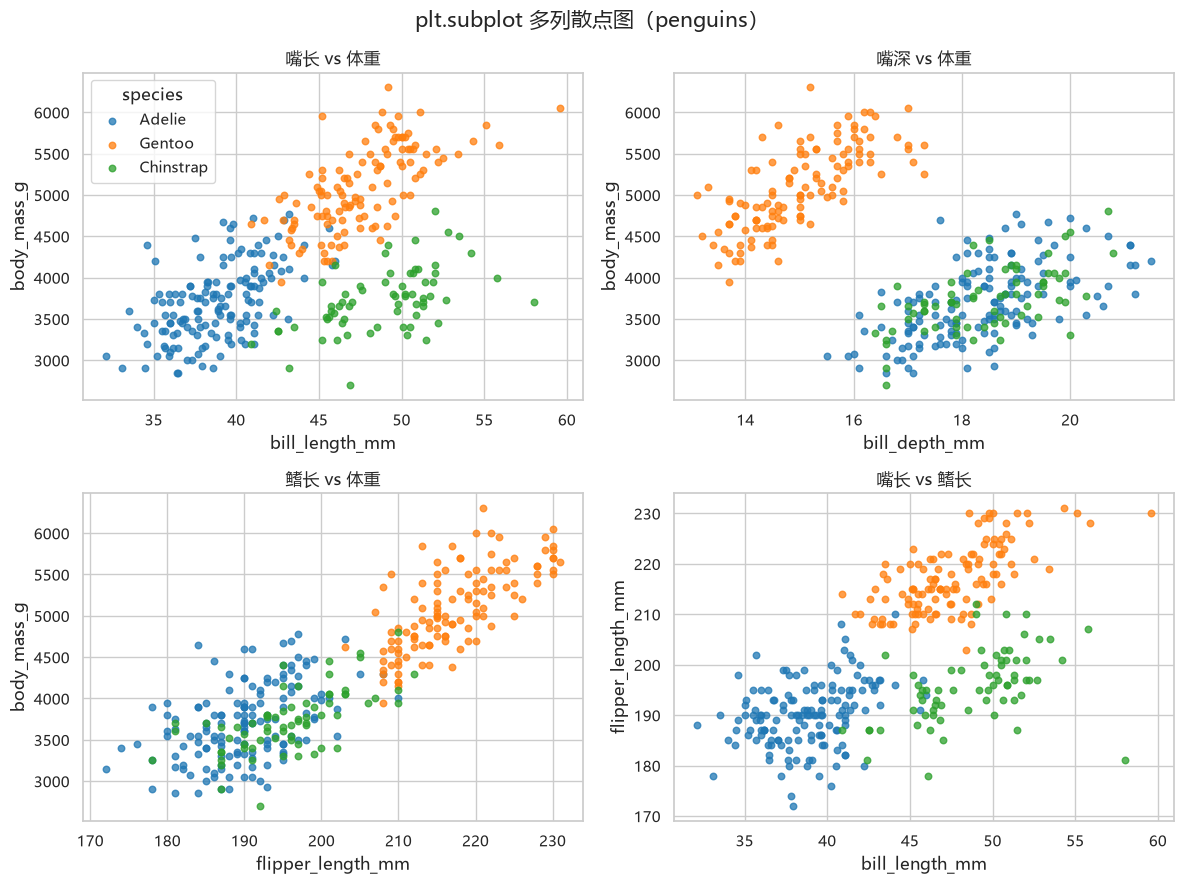

In [3]:
# 先载入 penguins 数据（删除缺失行）
penguins = sns.load_dataset("penguins").dropna()

combos = [
    ("bill_length_mm",   "body_mass_g",      "嘴长 vs 体重"),
    ("bill_depth_mm",    "body_mass_g",      "嘴深 vs 体重"),
    ("flipper_length_mm","body_mass_g",      "鳍长 vs 体重"),
    ("bill_length_mm",   "flipper_length_mm","嘴长 vs 鳍长"),
]
colors = {"Adelie": "#1f77b4", "Gentoo": "#ff7f0e", "Chinstrap": "#2ca02c"}

plt.figure(figsize=(12, 9))
for i, (x, y, title) in enumerate(combos, start=1):
    plt.subplot(2, 2, i)                     # 2行2列的第i个
    for sp, c in colors.items():
        sub = penguins[penguins["species"] == sp]
        plt.scatter(sub[x], sub[y], s=22, alpha=0.75, color=c, label=sp)
    plt.xlabel(x); plt.ylabel(y); plt.title(title)
    if i == 1:
        plt.legend(title="species")
plt.suptitle("plt.subplot 多列散点图（penguins）", fontsize=15)
plt.tight_layout()
plt.show()

## 第5题　画出箱线图，并解释箱体上的各个部分

C:\Users\Zaraughty\AppData\Local\Temp\ipykernel_38828\2461438047.py:4: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  bp = plt.boxplot(data, vert=True, patch_artist=True, widths=0.4,


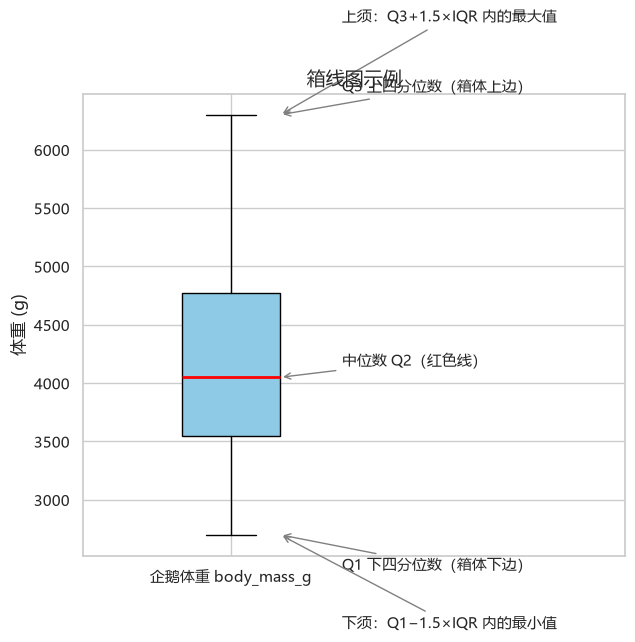

In [4]:
data = penguins["body_mass_g"]

plt.figure(figsize=(7, 6))
bp = plt.boxplot(data, vert=True, patch_artist=True, widths=0.4,
                 boxprops=dict(facecolor="#8ecae6"),
                 medianprops=dict(color="red", linewidth=2),
                 flierprops=dict(marker="o", markerfacecolor="orange"))
plt.xticks([1], ["企鹅体重 body_mass_g"])
plt.ylabel("体重 (g)")
plt.title("箱线图示例", fontsize=14)

# 标注箱体各部分
q1, med, q3 = bp["whiskers"][0].get_ydata()[1], bp["medians"][0].get_ydata()[1], bp["whiskers"][1].get_ydata()[1]
ann = dict(fontsize=11, arrowprops=dict(arrowstyle="->", color="gray"))
plt.annotate("上须：Q3+1.5×IQR 内的最大值", xy=(1.2, q3), xytext=(1.45, q3+800), **ann)
plt.annotate("Q3 上四分位数（箱体上边）", xy=(1.2, q3), xytext=(1.45, q3+200), **ann)
plt.annotate("中位数 Q2（红色线）", xy=(1.2, med), xytext=(1.45, med+100), **ann)
plt.annotate("Q1 下四分位数（箱体下边）", xy=(1.2, q1), xytext=(1.45, q1-300), **ann)
plt.annotate("下须：Q1−1.5×IQR 内的最小值", xy=(1.2, q1), xytext=(1.45, q1-800), **ann)
plt.xlim(0.4, 2.6)
plt.show()

**箱线图各部分解释：**

- **箱体（Box）**：从 **Q1（下四分位数，25%分位）** 到 **Q3（上四分位数，75%分位）**，箱内包含中间 50% 的数据，箱体长度 = **IQR（四分位距）**；
- **中位线（Median, Q2）**：箱体中间的粗线（图中红色），是数据的中位数，反映数据中心位置；
- **须线（Whisker）**：上下两条横线，延伸到 **Q1−1.5×IQR** 与 **Q3+1.5×IQR** 范围内的最小/最大观测值；
- **离群点（Outlier）**：须线之外的孤立点，即异常值；
- 通过比较中位线在箱体中的位置和须的长短，还可以判断数据的**偏态**和**离散程度**。

## 第6题*　seaborn penguins 数据集：特征探索 + 散点图、箱体图、小提琴图、成对图 + PCA

penguins 数据集包含 344 只企鹅的观测：3 个种类（Adelie、Chinstrap、Gentoo）、栖息岛屿、嘴长、嘴深、鳍长、体重、性别。

### 6.1 数据探索

In [5]:
df = sns.load_dataset("penguins")

print("数据形状：", df.shape)
print("\n前5行：")
display(df.head())
print("各列数据类型与缺失情况：")
df.info()
print("\n数值特征描述统计：")
display(df.describe().round(2))
print("种类分布：")
print(df["species"].value_counts())
print("\n各列缺失值数量：")
print(df.isna().sum())

# 删除缺失行，得到干净数据
df_clean = df.dropna().reset_index(drop=True)
print("\n删除缺失后的形状：", df_clean.shape)

数据形状： (344, 7)

前5行：


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female


各列数据类型与缺失情况：
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
dtypes: float64(4), str(3)
memory usage: 18.9 KB

数值特征描述统计：


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.00,342.00,342.00,342.00
mean,43.92,17.15,200.92,4201.75
std,5.46,1.97,14.06,801.95
min,32.10,13.10,172.00,2700.00
25%,39.22,15.60,190.00,3550.00
50%,44.45,17.30,197.00,4050.00
75%,48.50,18.70,213.00,4750.00
max,59.60,21.50,231.00,6300.00


种类分布：
species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64

各列缺失值数量：
species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

删除缺失后的形状： (333, 7)


### 6.2 散点图

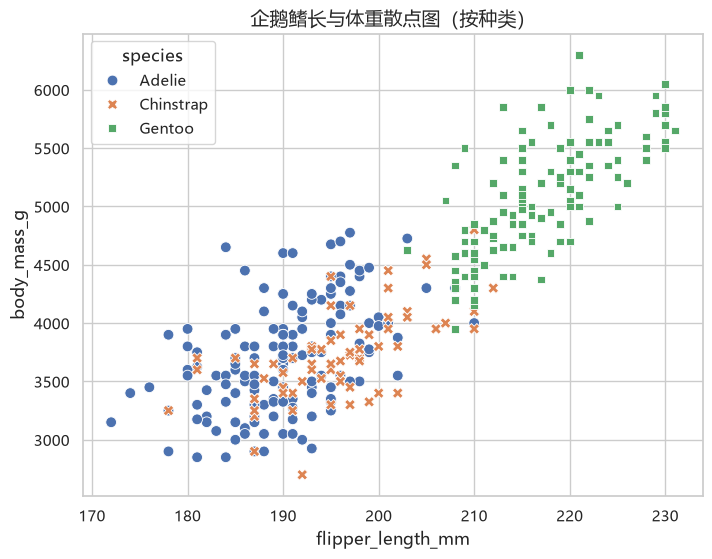

In [6]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df_clean, x="flipper_length_mm", y="body_mass_g",
                hue="species", style="species", s=60)
plt.title("企鹅鳍长与体重散点图（按种类）", fontsize=14)
plt.show()

### 6.3 箱体图

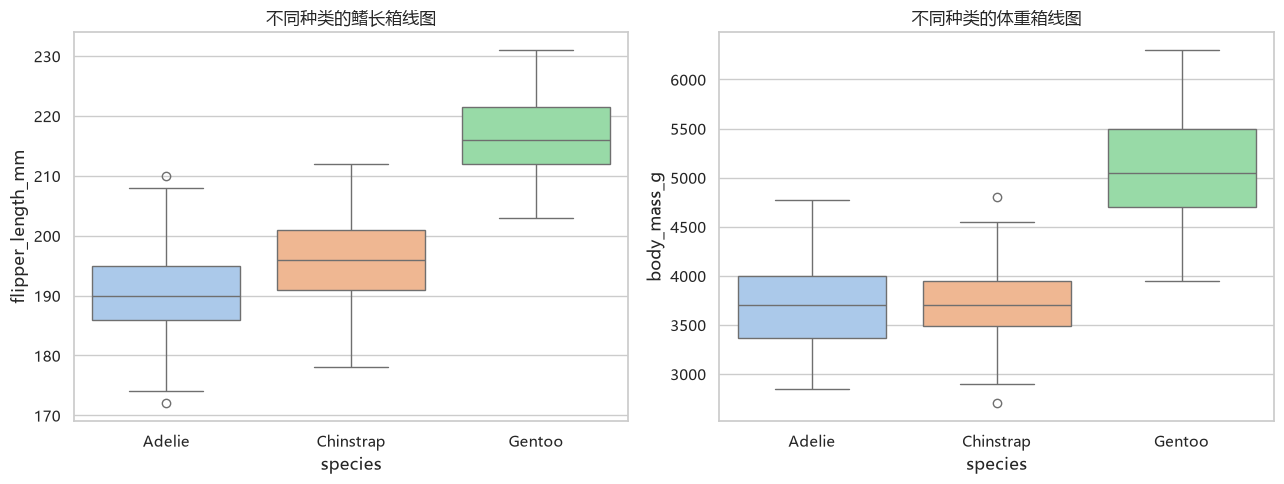

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=df_clean, x="species", y="flipper_length_mm", ax=axes[0],
            hue="species", palette="pastel")
axes[0].set_title("不同种类的鳍长箱线图")
sns.boxplot(data=df_clean, x="species", y="body_mass_g", ax=axes[1],
            hue="species", palette="pastel")
axes[1].set_title("不同种类的体重箱线图")
plt.tight_layout()
plt.show()

### 6.4 小提琴图

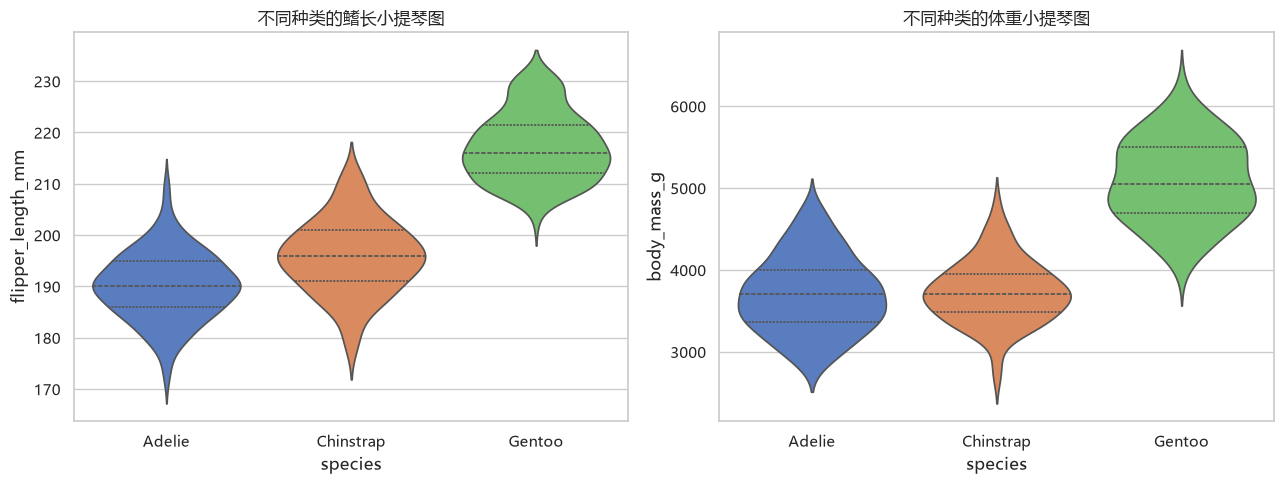

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.violinplot(data=df_clean, x="species", y="flipper_length_mm", ax=axes[0],
               hue="species", palette="muted", inner="quartile")
axes[0].set_title("不同种类的鳍长小提琴图")
sns.violinplot(data=df_clean, x="species", y="body_mass_g", ax=axes[1],
               hue="species", palette="muted", inner="quartile")
axes[1].set_title("不同种类的体重小提琴图")
plt.tight_layout()
plt.show()

### 6.5 成对图（pairplot）

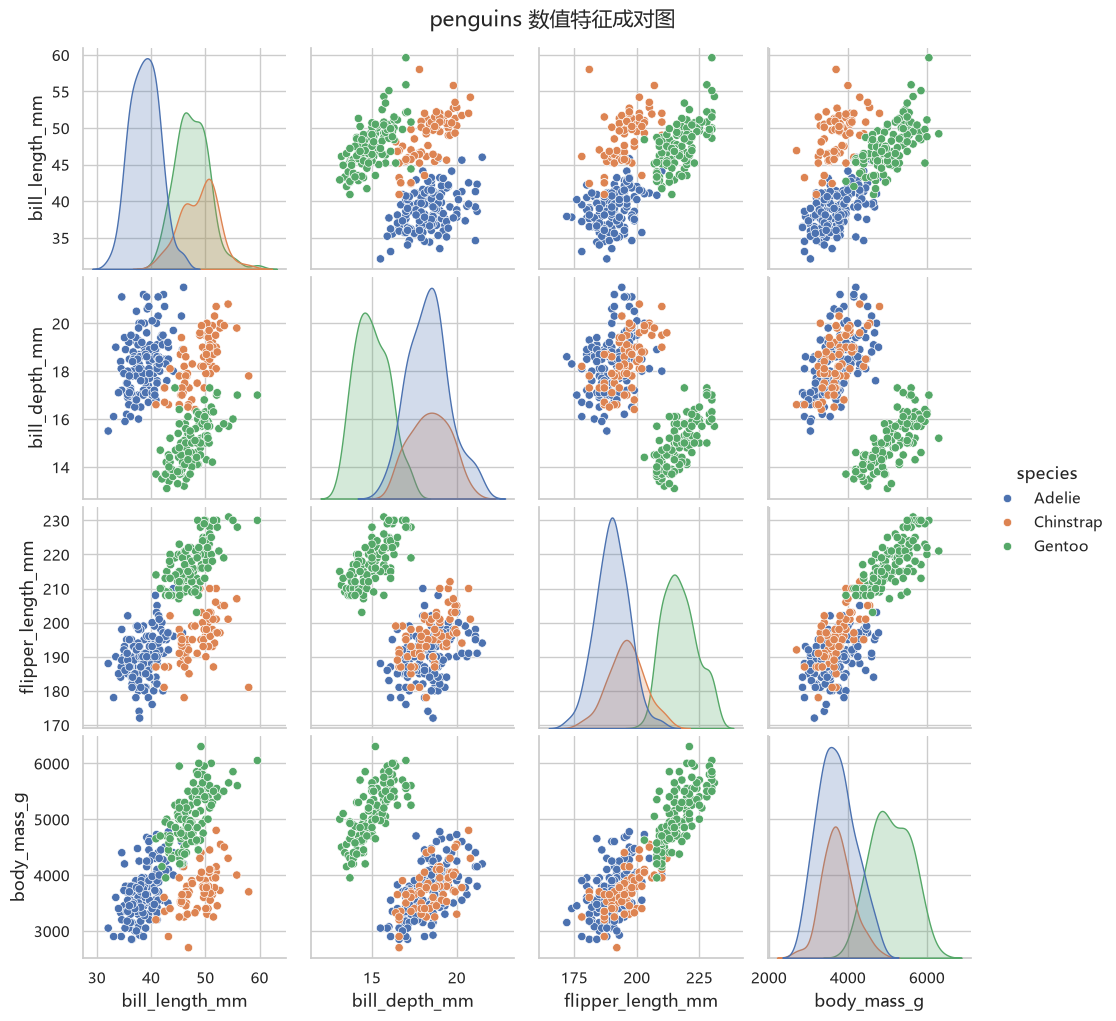

In [9]:
sns.pairplot(df_clean, hue="species", diag_kind="kde",
             vars=["bill_length_mm", "bill_depth_mm",
                   "flipper_length_mm", "body_mass_g"])
plt.suptitle("penguins 数值特征成对图", y=1.02, fontsize=15)
plt.show()

### 6.6 PCA 主成分分析

对 4 个数值特征先做标准化（Z-score），再用 PCA 降到 2 维，观察主成分解释方差比例及不同种类在主成分平面上的分布。

各主成分解释方差比例： [0.6863 0.1945]
累计解释方差：88.09%

主成分载荷（每个主成分是4个原始特征的线性组合）：


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
PC1,0.454,-0.399,0.577,0.550
PC2,0.600,0.796,0.006,0.076


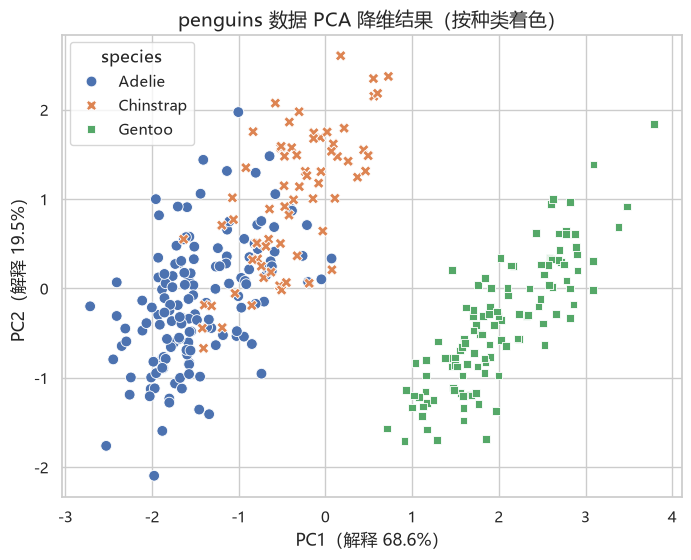

In [10]:
features = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm", "body_mass_g"]
X = df_clean[features].values
X_std = StandardScaler().fit_transform(X)      # 标准化

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_std)

print("各主成分解释方差比例：", pca.explained_variance_ratio_.round(4))
print("累计解释方差：%.2f%%" % (pca.explained_variance_ratio_.sum() * 100))
print("\n主成分载荷（每个主成分是4个原始特征的线性组合）：")
display(pd.DataFrame(pca.components_.round(3),
                     columns=features, index=["PC1", "PC2"]))

pca_df = pd.DataFrame(X_pca, columns=["PC1", "PC2"])
pca_df["species"] = df_clean["species"].values

plt.figure(figsize=(8, 6))
sns.scatterplot(data=pca_df, x="PC1", y="PC2", hue="species", style="species", s=60)
evr = pca.explained_variance_ratio_ * 100
plt.xlabel(f"PC1（解释 {evr[0]:.1f}%）")
plt.ylabel(f"PC2（解释 {evr[1]:.1f}%）")
plt.title("penguins 数据 PCA 降维结果（按种类着色）", fontsize=14)
plt.show()

**PCA 结果解读：**
- PC1 主要由嘴长、鳍长、体重（正向）与嘴深（负向）共同驱动，代表企鹅的"体型大小"；
- 前两个主成分累计解释 **88.1%** 的总方差（PC1: 68.6%，PC2: 19.4%），降维信息损失较小；
- 在 PC1–PC2 平面上，Gentoo 明显分离，Adelie 与 Chinstrap 有部分重叠但可区分，说明仅用 2 个主成分就能较好反映 3 个种类的形态差异。